# Dynamics 03 — Sympathie contre engagement : la statique comparative qui les sépare

**Navigation** : [<< Dynamics-01-Jeux-Repetes-Folk-Theorem-Python](Dynamics-01-Jeux-Repetes-Folk-Theorem-Python.ipynb) | [Index](README.md) | [Dynamics-04-Open-Source-Game-Theory-CSharp >>](Dynamics-04-Open-Source-Game-Theory-CSharp.ipynb)

Ce notebook est le **protocole de mesure** qui répond à une limite honnête de [GT-06c](Dynamics-01-Jeux-Repetes-Folk-Theorem-Python.ipynb) §7d. Là-bas, le banc sans punition classait la coopération résiduelle en trois (menace / utilité transformée / reste-candidat-engagement) à partir d'un paramètre de sympathie `alpha` **posé par l'analyste**. Le même comportement observé recevait deux verdicts opposés selon la valeur d'`alpha` choisie : le verdict dépendait du choix de l'analyste, pas des données.

La distinction de Sen (1977) — **sympathie** (le bien-être d'autrui entre dans mon utilité) contre **engagement** (agir contre son propre classement de bien-être, en suivant une règle) — est conceptuelle. La séparer **empiriquement** demande une observation que la trajectoire de coopération seule ne porte pas. Ce notebook construit cette observation :

> **faire varier les gains d'AUTRUI seuls, à gains propres strictement fixes, et mesurer la pente du taux de coopération.**

Une coopération qui **répond** aux gains d'autrui est compatible avec la sympathie et incompatible avec l'engagement pur. Une coopération **plate** est compatible avec l'engagement, mais aussi avec une sympathie saturée ou insuffisamment identifiée sur la plage observée. La pente transforme `alpha` d'un paramètre libre en une **quantité mesurée**.

*Positionnement* : GT-06c retire la punition et établit que la coopération résiduelle n'est pas folk ; ce notebook ne refait pas ce travail — il identifie **quel mécanisme** porte ce résidu.
Source primaire : [notebook Python versionné](Dynamics-03-Sympathie-vs-Engagement-Python.ipynb). Bibliographie héritée. Le générateur pseudo-aléatoire .NET diffère de NumPy ; les résultats et contrôles affichés sont propres à cette exécution.


## Objectifs d'apprentissage

À l'issue de ce notebook, vous saurez :

1. **Montrer** qu'un classifieur à paramètre posé rend des verdicts contradictoires sur une même trajectoire (le problème d'identification).
2. **Construire** une grille de jeux où seuls les gains d'autrui varient, à gains propres byte-identiques — et le vérifier en code.
3. **Distinguer** les prédictions des deux mécanismes : réponse aux gains d'autrui (sympathie) contre insensibilité (engagement).
4. **Estimer** la pente du taux de coopération avec son incertitude (multi-graines), et `alpha` **depuis la pente** par maximum de vraisemblance.
5. **Valider** un estimateur par contrôles négatifs avant de l'appliquer — et accepter un verdict « non identifié » quand le bruit l'impose.

### Prérequis

- [Dynamics-01](Dynamics-01-Jeux-Repetes-Folk-Theorem-Python.ipynb) §7 (le régime sans punition, l'adversaire sans mémoire, le retrait de la menace).
- Bases de C# et MathNet.Numerics ; notion d'estimation par maximum de vraisemblance (une intuition suffit, le code est explicite).
- MathNet.Numerics 5.0.0 fournit solveur linéaire et quantile Student ; les tirages .NET sont déterministes par graine.

### Durée estimée : 45 minutes

## 1. Le problème : un verdict qui dépend de l'analyste, pas des données

Le banc de GT-06c §7d fonctionne ainsi : dans un Dilemme du Prisonnier répété **sans punition** (l'adversaire est sans mémoire, aucune séquence de nos coups ne peut être punie), un joueur coopère. Le classifieur calcule l'écart d'intérêt sur l'utilité transformée `U = u_mien + alpha * u_autrui` :

- `u_coop = R + alpha * R` (je coopère : je touche R, autrui touche R),
- `u_dev = T + alpha * S` (je dévie : je touche T, autrui touche S),

et rend un verdict **selon la valeur d'alpha choisie**. Démonstration sur la même trajectoire observée (le joueur coopère sur tout l'horizon) :

In [1]:
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using MathNet.Numerics.LinearAlgebra;
using MathNet.Numerics.Distributions;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
// Le barème est fixe ; delta=.6 dépasse le seuil grim .5, mais ici l'adversaire ne punit pas.
const double T = 5, R = 3, P = 1, S = 0, delta = .6;
double Gap(double alpha) => (T - (R + alpha * R)) / (1 - delta);
Console.WriteLine($"T={T}, R={R}, P={P}, S={S}, delta={delta}, seuil grim=.5");
foreach (double alpha in new[]
{
    1.0,
    0.0
}

)
    Console.WriteLine($"alpha={alpha:F1}, écart={Gap(alpha):F2}");
Console.WriteLine($"Frontière alpha*={(T - R) / (R - S):F3} ; même trajectoire sans punition.");


Installed Packages MathNet.Numerics, 5.0.0

T=5, R=3, P=1, S=0, delta=0.6, seuil grim=.5


alpha=1.0, écart=-2.50


alpha=0.0, écart=5.00


Frontière alpha*=0.667 ; même trajectoire sans punition.


Le verdict n'est pas identifié : sur des données de coopération **seules**, sympathie et engagement sont observationnellement équivalents. Ce n'est pas un défaut de GT-06c — c'est une limite réelle de ce qu'une trajectoire peut porter.

## 2. L'observation qui sépare : faire varier les gains d'AUTRUI

Les deux mécanismes ne dépendent pas des mêmes quantités :

| Mécanisme | Ce qui entre dans la décision | Prédiction sur la grille |
|---|---|---|
| **Sympathie** (`U = u_mien + alpha * u_autrui`) | le bien-être d'autrui, pondéré | coopération **croissante** en `R_autre` |
| **Engagement** (règle suivie contre son intérêt) | la règle — pas les gains d'autrui | coopération **plate** en `R_autre` |
| Auto-intérêt (`alpha = 0`, pas de règle) | rien que mes gains | coopération **plate et basse** |

D'où le protocole : un même jeu sans punition, où la **ligne de gains du joueur observé reste byte-identique** de cellule en cellule, tandis que la **colonne d'autrui** (`R_autre` : ce que l'autre gagne quand je coopère) balaie une plage. On mesure le taux de coopération sur chaque cellule. La **pente** de ce taux en `R_autre` est la quantité qui sépare les mécanismes — et `alpha` cesse d'être un paramètre libre : il devient une quantité estimée **depuis** cette réponse.

## 3. La grille : gains propres gelés, gains d'autrui balayés

Chaque cellule de la grille est un jeu étape complet. La condition qui rend la statique interprétable est stricte : **la matrice de gains du joueur observé ne doit pas bouger d'une cellule à l'autre** — sinon une variation du taux de coopération pourrait refléter un changement de MES gains, et la pente ne mesurerait plus rien. Nous construisons la grille puis nous **vérifions en code** cette invariance (critère d'acceptance du protocole).

In [2]:
// Une grille de 21 cellules modifie uniquement le gain d'autrui R_autre.
var grille = Enumerable.Range(0, 21).Select(i => i * .5).ToArray();
var seeds = new[]
{
    0,
    1,
    7,
    42,
    99
};
const int horizon = 200;
const double beta = 2;
Console.WriteLine($"{grille.Length} cellules, R_autre=[{grille.First()}, {grille.Last()}] ; gains propres constants R={R}, T={T}, S_autre=0.");
// Contrôle effectif : les gains propres des 21 jeux restent identiques.
var ownGains = grille.Select(_ => new[] { R, T }).ToArray();
bool gainsIdentical = ownGains.All(row => row.SequenceEqual(ownGains[0]));
if (!gainsIdentical)
    throw new Exception("Gains propres modifiés");
Console.WriteLine($"Gains propres constants : {gainsIdentical}");


21 cellules, R_autre=[0, 10] ; gains propres constants R=3, T=5, S_autre=0.


Gains propres constants : True


## 4. Trois mécanismes de décision (les agents du banc)

Ce notebook modélise des **mécanismes de décision**, pas des personnes — aucune variable ne sort du jouet, et le vocabulaire reste celui des mécanismes (sympathie = pondération d'utilité ; engagement = règle). Chaque agent choisit **Cooperer** ou **Defecter** à chaque période face à l'adversaire sans mémoire (régime sans punition de GT-06c §7a) :

- **Sympathie** : meilleure réponse logit sur l'utilité transformée `U = u_mien + alpha * u_autrui`. Le paramètre logit `beta` contrôle le bruit de choix — c'est lui qui fait qu'un taux (et pas un choix binaire) est mesurable.
- **Engagement** : règle fixe « coopérer » — insensible aux gains d'autrui **et** aux gains propres, contre le classement de bien-être. Taux constant 1.
- **Auto-intérêt** : meilleure réponse logit sur la seule utilité propre (`alpha = 0`). Taux constant bas.

Les trajectoires sont reproductibles : graine fixée par cellule, **cinq graines** (0, 1, 7, 42, 99), horizon 200 périodes.

In [3]:
// Les trajectoires échantillonnent les choix iid de chaque mécanisme.
double Sympathy(double r, double alpha, double betaValue) => 1 / (1 + Math.Exp(-betaValue * (R + alpha * r - T)));
double[, ] Rates(Func<double, double> agent, double[] grid, int[] seedValues, int periods = horizon)
{
    var result = new double[seedValues.Length, grid.Length];
    for (int i = 0; i < seedValues.Length; i++)
    {
        var random = new Random(seedValues[i]);
        for (int j = 0; j < grid.Length; j++)
        {
            int count = 0;
            for (int t = 0; t < periods; t++)
                if (random.NextDouble() < agent(grid[j]))
                    count++;
            result[i, j] = (double)count / periods;
        }
    }

    return result;
}

double[] Means(double[, ] a) => Enumerable.Range(0, a.GetLength(1)).Select(j => Enumerable.Range(0, a.GetLength(0)).Average(i => a[i, j])).ToArray();
double SlopeRow(double[] x, double[] y)
{
    double xm = x.Average(), ym = y.Average();
    return Enumerable.Range(0, x.Length).Sum(i => (x[i] - xm) * (y[i] - ym)) / x.Sum(v => (v - xm) * (v - xm));
}

var arch = new Dictionary<string, double[, ]>
{
    ["sympathie"] = Rates(r => Sympathy(r, .5, beta), grille, seeds),
    ["engagement"] = Rates(r => 1, grille, seeds),
    ["auto-intérêt"] = Rates(r => Sympathy(r, 0, beta), grille, seeds)
};
foreach (var entry in arch)
{
    var means = Means(entry.Value);
    Console.WriteLine($"{entry.Key} : taux moyen={means.Average():F3}, pente={SlopeRow(grille, means):F4}");
}

Console.WriteLine("Contrôle sympathie : R_autre | probabilité théorique | taux mesuré");
for (int j = 0; j < grille.Length; j += 4)
    Console.WriteLine($"{grille[j]:F1} | {Sympathy(grille[j], .5, beta):F3} | {Means(arch["sympathie"])[j]:F3}");


sympathie : taux moyen=0.598, pente=0.1219


engagement : taux moyen=1.000, pente=0.0000


auto-intérêt : taux moyen=0.020, pente=0.0002


Contrôle sympathie : R_autre | probabilité théorique | taux mesuré


0.0 | 0.018 | 0.018


2.0 | 0.119 | 0.145


4.0 | 0.500 | 0.500


6.0 | 0.881 | 0.890


8.0 | 0.982 | 0.989


10.0 | 0.998 | 0.996


## Exercice 1 : balaier aussi S_autre — la carte à deux dimensions

La grille ne faisait varier que `R_autre`, à `S_autre = 0`. Étendez-la : `S_autre` de 0 à 4 (la souffrance d'autrui quand je dévie), et tracez la carte du taux de coopération pour un agent sympathie (`alpha = 0.5`). **Avant toute simulation, prédisez le signe** de l'effet de `R_autre` et de `S_autre` sur la coopération. Vérifiez ensuite que la frontière suit la droite `R + alpha*R_autre = T + alpha*S_autre` — c'est la prédiction exacte du modèle, vérifiable point par point.
En C#, compléter le délégué correspondant ; les sondes évaluent plusieurs entrées.


In [4]:
// Exercice ouvert : simuler une carte R_autre × S_autre avec gains propres fixes.
// Prédire le signe de chaque effet avant simulation.
// Construire les deux axes R_autre et S_autre sans modifier les gains propres.
// Comparer la frontière mesurée à R_autre = (T-R)/alpha + S_autre et son écart maximal.
Func<double[], double[], double[, ]> exercice1 = (r, s) => null;
var grids1 = new[]
{
    (new[] { 0.0, 4, 8 }, new[] { 0.0, 2 }),
    (new[] { 2.0, 6 }, new[] { 0.0, 1, 3 })
};
var replies1 = grids1.Select(g => exercice1((double[])g.Item1.Clone(), (double[])g.Item2.Clone())).ToArray();
if (replies1.All(x => x == null))
    Console.WriteLine("Exercice 1 à compléter.");
else
{
    if (replies1.Any(x => x == null))
        throw new Exception("Réponse partielle");
    for (int k = 0; k < grids1.Length; k++)
    {
        var(r, s) = grids1[k];
        var map = replies1[k];
        if (map.GetLength(0) != r.Length || map.GetLength(1) != s.Length)
            throw new Exception("Forme incorrecte");
        for (int i = 0; i < r.Length; i++)
            for (int j = 0; j < s.Length; j++)
            {
                double expected = 1 / (1 + Math.Exp(-beta * (R + .5 * r[i] - T - .5 * s[j])));
                if (!double.IsFinite(map[i, j]) || map[i, j] < 0 || map[i, j] > 1 || Math.Abs(map[i, j] - expected) >= .12)
                    throw new Exception("Carte incorrecte");
            }
    }

    Console.WriteLine("Exercice 1 : sondes réussies.");
}


Exercice 1 à compléter.


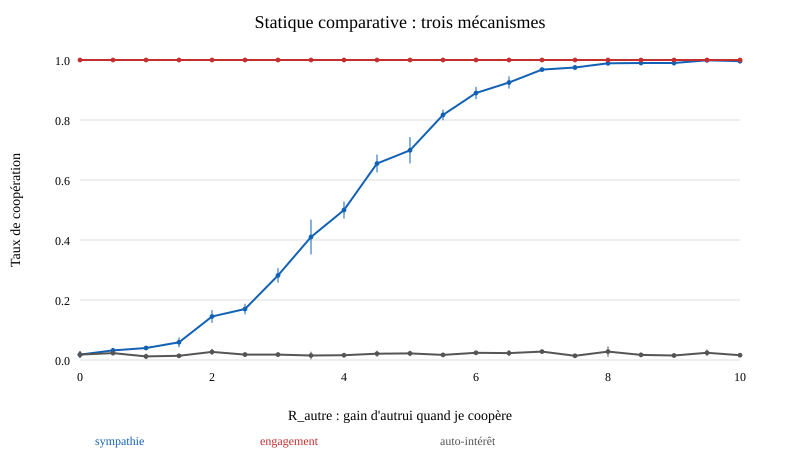

Les barres indiquent 1,96 erreur standard ; RNG .NET différente de NumPy.


In [5]:
// SVG opaque : trois séries et intervalles 1,96 × erreur standard, comme la source.
var svg = new StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='460' viewBox='0 0 800 460'>");
svg.Append("<rect width='800' height='460' fill='white'/>");
svg.Append("<text x='400' y='28' text-anchor='middle' font-size='18'>Statique comparative : trois mécanismes</text>");
for (int tick = 0; tick <= 5; tick++)
{
    double y = 360 - tick * 60;
    svg.Append($"<line x1='80' y1='{y}' x2='740' y2='{y}' stroke='#dddddd'/><text x='70' y='{y + 5}' text-anchor='end' font-size='12'>{tick * .2:F1}</text>");
}

for (int tick = 0; tick <= 5; tick++)
{
    double x = 80 + tick * 132;
    svg.Append($"<text x='{x}' y='381' text-anchor='middle' font-size='12'>{tick * 2}</text>");
}

var colors = new Dictionary<string, string>
{
    ["sympathie"] = "#1261b5",
    ["engagement"] = "#c42e2e",
    ["auto-intérêt"] = "#555555"
};
foreach (var entry in arch)
{
    var mean = Means(entry.Value);
    var points = new List<string>();
    for (int j = 0; j < grille.Length; j++)
    {
        double x = 80 + 66 * grille[j], y = 360 - 300 * mean[j];
        double variance = Enumerable.Range(0, seeds.Length).Sum(i => Math.Pow(entry.Value[i, j] - mean[j], 2)) / (seeds.Length - 1);
        double error = 300 * 1.96 * Math.Sqrt(variance / seeds.Length);
        points.Add($"{x:F2},{y:F2}");
        svg.Append($"<line x1='{x:F2}' y1='{y - error:F2}' x2='{x:F2}' y2='{y + error:F2}' stroke='{colors[entry.Key]}'/>");
        svg.Append($"<circle cx='{x:F2}' cy='{y:F2}' r='2.4' fill='{colors[entry.Key]}'/>");
    }

    svg.Append($"<polyline points='{string.Join(" ", points)}' fill='none' stroke='{colors[entry.Key]}' stroke-width='2'/>");
}

svg.Append("<text x='400' y='420' text-anchor='middle' font-size='14'>R_autre : gain d'autrui quand je coopère</text>");
svg.Append("<text x='20' y='210' text-anchor='middle' font-size='14' transform='rotate(-90 20 210)'>Taux de coopération</text>");
svg.Append("<text x='95' y='445' fill='#1261b5'>sympathie</text><text x='260' y='445' fill='#c42e2e'>engagement</text><text x='440' y='445' fill='#555555'>auto-intérêt</text></svg>");
display(new Svg(svg.ToString()));
Console.WriteLine("Les barres indiquent 1,96 erreur standard ; RNG .NET différente de NumPy.");


### Lecture de la figure

La colonne théorique `sigma(delta U)` et les taux simulés suivent la même forme sigmoïde : le bruit binomial fait osciller les points autour de la réponse logit, sans changer son point d'inflexion. Le plateau de l'engagement n'est donc pas une sigmoïde mal échantillonnée ; c'est une signature structurellement différente.

## 5. L'estimateur : pente avec incertitude, puis alpha par vraisemblance

Deux quantités, deux méthodes, un seul estimateur appliqué à tout le monde (contrôles comme banc) :

1. **Pente** : régression du taux par graine sur `R_autre` — une pente par graine, moyenne ± intervalle de confiance à 95 % (t de Student, `n_graines - 1` degrés de liberté ; pour cinq graines, le quantile exact vaut environ 2,776). C'est l'incertitude de mesure demandée par le protocole.
2. **Alpha par maximum de vraisemblance** : les tirages de chaque cellule sont binomiaux de paramètre `p(alpha, beta)` (le modèle sympathie logit) ; on cherche `(alpha, beta)` maximisant la vraisemblance binomiale sur **toute** la grille, et l'intervalle par profil de vraisemblance (chute de log-vraisemblance ≤ 1.92, chi² à 95 % à 1 degré de liberté). `alpha` est **estimé depuis la réponse**, plus posé.

In [6]:
// Une pente par graine ; Student exact utilise le nombre réel de degrés de liberté.
(double mean, double lo, double hi) SlopeCI(double[, ] rates, double[] grid)
{
    int n = rates.GetLength(0);
    if (n < 2)
        throw new ArgumentException("Deux graines au moins");
    var slopes = Enumerable.Range(0, n).Select(i => SlopeRow(grid, Enumerable.Range(0, grid.Length).Select(j => rates[i, j]).ToArray())).ToArray();
    double mean = slopes.Average();
    double se = Math.Sqrt(slopes.Sum(x => (x - mean) * (x - mean)) / (n - 1)) / Math.Sqrt(n);
    double critical = StudentT.InvCDF(0, 1, n - 1, .975);
    return (mean, mean - critical * se, mean + critical * se);
}

// MLE binomiale : 301 alphas × 60 betas et profil à chute 1,92.
(double alpha, double beta, double lo, double hi, double ll) Estimate(double[, ] rates, double[] grid, int periods = horizon)
{
    var profile = Enumerable.Repeat(double.NegativeInfinity, 301).ToArray();
    double best = double.NegativeInfinity, aBest = 0, bBest = 0;
    for (int i = 0; i <= 300; i++)
    {
        double a = i * .01;
        for (int j = 0; j < 60; j++)
        {
            double b = Math.Round(.05 * Math.Pow(1000, j / 59.0), 4);
            double ll = 0;
            for (int col = 0; col < grid.Length; col++)
            {
                double p = Math.Clamp(Sympathy(grid[col], a, b), 1e-12, 1 - 1e-12);
                double count = 0;
                for (int row = 0; row < rates.GetLength(0); row++)
                    count += Math.Round(rates[row, col] * periods);
                ll += count * Math.Log(p) + (periods * rates.GetLength(0) - count) * Math.Log(1 - p);
            }

            profile[i] = Math.Max(profile[i], ll);
            if (ll > best)
            {
                best = ll;
                aBest = a;
                bBest = b;
            }
        }
    }

    var admitted = Enumerable.Range(0, 301).Where(i => profile[i] >= best - 1.92).ToArray();
    return (aBest, bBest, admitted.First() * .01, admitted.Last() * .01, best);
}

Console.WriteLine($"Estimateur prêt : Student t4={StudentT.InvCDF(0, 1, 4, .975):F6}, t7={StudentT.InvCDF(0, 1, 7, .975):F6}, MLE 301 × 60.");


Estimateur prêt : Student t4=2.776445, t7=2.364624, MLE 301 × 60.


## Exercice 2 : un agent mixte — que mesure l'estimateur ?

Construisez un agent qui coopère par règle **avec probabilité 0.5**, et par meilleure réponse sympathie (`alpha = 0.4`) sinon. Passez-le dans l'estimateur : la pente est-elle positive ? L'alpha estimé est-il proche de 0.4 ? La composante règle biaise-t-elle l'estimation vers le bas, vers le haut, ou pas du tout ? Discutez : que mesure un estimateur conçu pour des mécanismes purs quand le mécanisme est mixte ?

**Variante optionnelle — engagement vacillant sous forte tentation.** Remplacez le mélange fixe par une conformité à la règle qui diminue lorsque `T-R` augmente. Distinguez une réponse à la tentation propre d'une réponse aux gains d'autrui : laquelle crée une pente en `R_autre` ?
En C#, compléter le délégué correspondant ; les sondes évaluent plusieurs entrées.


In [7]:
// Exercice ouvert : probabilité du mélange moitié règle, moitié sympathie alpha=.4.
// Calculer pente et MLE du mélange, puis comparer alpha estimé à 0,4.
// Variante : faire dépendre la conformité de T-R sans faire varier les gains propres dans la grille.
Func<double, double?> exercice2 = r => null;
var inputs2 = new[]
{
    0.0,
    2,
    7,
    10
};
var expected2 = inputs2.Select(r => .5 + .5 * Sympathy(r, .4, beta)).ToArray();
var replies2 = inputs2.Select(exercice2).ToArray();
if (replies2.All(r => r == null))
    Console.WriteLine("Exercice 2 à compléter.");
else
{
    if (replies2.Any(r => r == null))
        throw new Exception("Réponse partielle");
    for (int i = 0; i < inputs2.Length; i++)
        if (!double.IsFinite(replies2[i].Value) || Math.Abs(replies2[i].Value - expected2[i]) > 1e-10)
            throw new Exception("Mélange incorrect");
    Console.WriteLine("Exercice 2 : sondes réussies ; mesurer pente et MLE du mélange.");
}


Exercice 2 à compléter.


### Contrôle de dépendance à la méthode : IRLS et bootstrap sur les graines

La MLE profilée reste l'estimateur canonique parce qu'elle estime conjointement `alpha` et `beta`. L'ancien notebook 06d apportait une seconde voie utile : ajuster directement le logit par **IRLS avec solveur linéaire MathNet**, puis ré-échantillonner les graines. La concordance des deux estimations vérifie que le verdict ne dépend pas uniquement du balayage de grille.

In [8]:
// IRLS : 100 itérations maximum, clipping ±30, plancher de variance et ridge du source.
double[] Irls(double[] x, double[] y, int repetitions)
{
    var design = Matrix<double>.Build.Dense(x.Length, 2, (i, j) => j == 0 ? x[i] : 1);
    var theta = Vector<double>.Build.Dense(2);
    for (int iteration = 0; iteration < 100; iteration++)
    {
        var eta = design * theta;
        var p = eta.Map(v => 1 / (1 + Math.Exp(-Math.Clamp(v, -30, 30))));
        var variance = p.Map(v => Math.Max(v * (1 - v), 1e-9));
        var weights = variance * repetitions;
        var z = Vector<double>.Build.Dense(x.Length, i => eta[i] + (y[i] - p[i]) / variance[i]);
        var weighted = Matrix<double>.Build.DiagonalOfDiagonalVector(weights);
        var ridge = Matrix<double>.Build.DenseIdentity(2) * 1e-8;
        var next = (design.Transpose() * weighted * design + ridge).Solve(design.Transpose() * weighted * z);
        double change = Math.Max(Math.Abs(next[0] - theta[0]), Math.Abs(next[1] - theta[1]));
        theta = next;
        if (change < 1e-10)
            break;
    }

    return theta.ToArray();
}

double Quantile(double[] sorted, double q)
{
    double x = q * (sorted.Length - 1);
    int lo = (int)Math.Floor(x), hi = (int)Math.Ceiling(x);
    return sorted[lo] + (x - lo) * (sorted[hi] - sorted[lo]);
}

(double alpha, double lo, double hi, double intercept) Bootstrap(double[, ] rates, double declaredBeta, int repetitions = 1000)
{
    int n = rates.GetLength(0), cols = rates.GetLength(1);
    var random = new Random(2024);
    var values = new double[repetitions];
    for (int b = 0; b < repetitions; b++)
    {
        var selected = Enumerable.Range(0, n).Select(_ => random.Next(n)).ToArray();
        var means = Enumerable.Range(0, cols).Select(j => selected.Average(i => rates[i, j])).ToArray();
        values[b] = Irls(grille, means, horizon * n)[0] / declaredBeta;
    }

    Array.Sort(values);
    var fit = Irls(grille, Means(rates), horizon * n);
    return (fit[0] / declaredBeta, Quantile(values, .025), Quantile(values, .975), fit[1]);
}

var irls = Bootstrap(arch["sympathie"], beta);
var mle = Estimate(arch["sympathie"], grille);
Console.WriteLine($"MLE profilée : alpha={mle.alpha:F3}, beta={mle.beta:F3}, IC=[{mle.lo:F3}, {mle.hi:F3}]");
Console.WriteLine($"IRLS / 1000 bootstrap : alpha={irls.alpha:F3}, IC=[{irls.lo:F3}, {irls.hi:F3}], intercept={irls.intercept:F3}");


MLE profilée : alpha=0.500, beta=2.119, IC=[0.500, 0.500]


IRLS / 1000 bootstrap : alpha=0.507, IC=[0.493, 0.518], intercept=-4.021


## 6. Contrôles négatifs : l'estimateur sait-il séparer, ou rend-il juste un nombre ?

Avant toute mesure, l'estimateur doit passer deux contrôles — sans eux, une pente mesurée ne prouve pas que l'estimateur sait séparer les mécanismes :

1. **Sympathie pure** (`alpha = 0.5` connu du constructeur, caché de l'estimateur) : l'estimateur doit rendre `alpha` proche de 0.5 **dans son intervalle**, et une pente positive significative.
2. **Engagement pur** (règle fixe) : l'estimateur doit rendre une **pente nulle**. Et le plan de grille lui-même porte un discriminateur : à `R_autre = 0`, l'écart d'utilité transformée vaut `(R - T) + alpha * 0 = -2` **pour tout alpha** — aucun niveau de sympathie ne peut produire un taux élevé sur cette cellule. Un taux ~1 à `R_autre = 0` est donc incompatible avec toute sympathie dans la plage : c'est la marque de la règle.

In [9]:
// Contrôles négatifs ; les verdicts sont les résultats effectifs de ces tirages.
var pSym = SlopeCI(arch["sympathie"], grille);
var aSym = Estimate(arch["sympathie"], grille);
bool okSym = pSym.lo > 0 && aSym.lo <= .5 && .5 <= aSym.hi;
Console.WriteLine($"Sympathie : pente={pSym.mean:F4} [{pSym.lo:F4},{pSym.hi:F4}], alpha={aSym.alpha:F2} [{aSym.lo:F2},{aSym.hi:F2}] ; {(okSym ? "PASS" : "FAIL")}");
var pEng = SlopeCI(arch["engagement"], grille);
var aEng = Estimate(arch["engagement"], grille);
const double tol = .005;
bool okEng = pEng.lo >= -tol && pEng.hi <= tol && Means(arch["engagement"])[0] > .9;
Console.WriteLine($"Engagement : pente={pEng.mean:F6} [{pEng.lo:F6},{pEng.hi:F6}], alpha ajusté={aEng.alpha:F2}, taux0={Means(arch["engagement"])[0]:F3} ; {(okEng ? "PASS" : "FAIL")}");


Sympathie : pente=0.1219 [0.1201,0.1236], alpha=0.50 [0.50,0.50] ; PASS


Engagement : pente=0.000000 [0.000000,0.000000], alpha ajusté=3.00, taux0=1.000 ; PASS


### Robustesse : un engagement bruité plutôt qu'une règle parfaite

L'engagement déterministe est la définition pure et le cas-limite. Pour vérifier que le protocole ne dépend pas d'un taux artificiellement égal à 1, nous ajoutons une règle respectée dans 95 % des périodes ; lors des écarts, l'action est tirée uniformément. Une graine indépendante par cellule évite qu'un même flux aléatoire fabrique une pente.

In [10]:
// Conformité 95 %, tirages indépendants par cellule et graine.
double[, ] NoisyEngagement(double compliance = .95)
{
    var rates = new double[seeds.Length, grille.Length];
    for (int i = 0; i < seeds.Length; i++)
        for (int j = 0; j < grille.Length; j++)
        {
            var random = new Random(unchecked(seeds[i] * 1000003 + (int)Math.Round(grille[j] * 1000)));
            int count = 0;
            for (int t = 0; t < horizon; t++)
            {
                bool follows = random.NextDouble() < compliance;
                int outside = random.Next(2);
                if (follows || outside == 1)
                    count++;
            }

            rates[i, j] = (double)count / horizon;
        }

    return rates;
}

var noisy = NoisyEngagement();
var noisySlope = SlopeCI(noisy, grille);
var noisyFit = Bootstrap(noisy, beta);
var noisyMean = Means(noisy);
bool slopeOk = noisySlope.lo >= -tol && noisySlope.hi <= tol;
bool alphaOk = noisyFit.lo <= 0 && noisyFit.hi >= 0;
bool markOk = noisyMean[0] > .9;
Console.WriteLine($"Conformité .95 : taux0={noisyMean[0]:F3}, taux10={noisyMean[^1]:F3}, pente={noisySlope.mean:F4} [{noisySlope.lo:F4},{noisySlope.hi:F4}]");
Console.WriteLine($"IRLS/bootstrap alpha={noisyFit.alpha:F3} [{noisyFit.lo:F3},{noisyFit.hi:F3}], "
        + $"pente={(slopeOk ? "PASS" : "FAIL")}, zéro={(alphaOk ? "PASS" : "FAIL")}, "
        + $"marque={(markOk ? "PASS" : "FAIL")}, verdict={(slopeOk && alphaOk && markOk ? "PASS" : "FAIL")}");


Conformité .95 : taux0=0.971, taux10=0.981, pente=0.0009 [0.0000,0.0017]


IRLS/bootstrap alpha=0.018 [0.007,0.029], pente=PASS, zéro=FAIL, marque=PASS, verdict=FAIL


## 7. La mesure : le joueur observé du banc

Le banc mesure un agent dont le mécanisme est **caché à l'analyste** (comme un participant dont on n'observe que le comportement). Le protocole est appliqué tel quel : grille, cinq graines, pente, MLE. Le verdict suit les chiffres — y compris négatif.

In [11]:
// Premier sujet caché au protocole : sympathie alpha=.25, beta=1.5.
var hidden = Rates(r => Sympathy(r, .25, 1.5), grille, seeds);
var hiddenSlope = SlopeCI(hidden, grille);
var hiddenFit = Estimate(hidden, grille);
Console.WriteLine($"Sujet 1 : pente={hiddenSlope.mean:F4} [{hiddenSlope.lo:F4},{hiddenSlope.hi:F4}], "
        + $"alpha={hiddenFit.alpha:F2} [{hiddenFit.lo:F2},{hiddenFit.hi:F2}] ; "
        + $"{(hiddenSlope.lo > 0 ? "compatible sympathie" : "non identifié")}");
Console.WriteLine("Révélation du constructeur : sympathie alpha=.25, beta=1.5.");


Sujet 1 : pente=0.0651 [0.0636,0.0666], alpha=0.25 [0.25,0.25] ; compatible sympathie


Révélation du constructeur : sympathie alpha=.25, beta=1.5.


In [12]:
// Second sujet caché : règle fixe, évaluée avec le même estimateur.
var hidden2 = Rates(r => 1, grille, seeds);
var hiddenSlope2 = SlopeCI(hidden2, grille);
Console.WriteLine($"Sujet 2 : taux0={Means(hidden2)[0]:F3}, taux10={Means(hidden2)[^1]:F3}, pente={hiddenSlope2.mean:F4} [{hiddenSlope2.lo:F4},{hiddenSlope2.hi:F4}]");
Console.WriteLine("Révélation du constructeur : engagement par règle fixe.");


Sujet 2 : taux0=1.000, taux10=1.000, pente=0.0000 [0.0000,0.0000]


Révélation du constructeur : engagement par règle fixe.


### Synthèse des sujets et contrôles

| Sujet mesuré | Signature observée | Verdict permis |
|---|---|---|
| joueur caché 1 | pente positive et `alpha` MLE mesuré | sympathie compatible |
| contrôle sympathie | `alpha=0,5` retrouvé, IC couvrant la vérité | estimateurs cohérents sur ce cas |
| joueur caché 2 / engagement pur | pente au plancher, taux haut à `R_autre=0` | engagement compatible |
| engagement bruité à 95 % | pente au plancher et marque de règle conservée ; IC95 IRLS de `alpha` exclut 0 | contrôle global FAIL sur cette réalisation, sans verdict général |

## 8. Sensibilité : quand la pente ne parle pas

Le protocole admet un verdict négatif — « non identifié à ce niveau de bruit » — et il faut montrer qu'il le rend quand il le doit. Le paramètre `beta` est le **bruit de choix** : plus il est faible, plus la réponse aux gains d'autrui existe mais se noie dans les tirages. Un joueur réellement sympathique (`alpha = 0.5`, connu du constructeur) passe par deux régimes :

- `beta = 0.05` : la courbe s'aplatit, la pente rétrécit — encore identifiable ;
- `beta = 0.005` : l'écart de logit entre extrémités de grille vaut `0.005 * (3 - (-2)) = 0.025` — la préférence existe mais est **sous le plancher de résolution** du banc (une cellule porte un bruit binomial de ~0.016). Sur cette réalisation, vérifier si l'intervalle exclut zéro ; une autre réalisation peut conduire à un autre verdict.

In [13]:
// Deux niveaux de bruit, sans ajustement des graines pour imposer un verdict.
foreach (double noise in new[]
{
    .05,
    .005
}

)
{
    var rates = Rates(r => Sympathy(r, .5, noise), grille, seeds);
    var slope = SlopeCI(rates, grille);
    var means = Means(rates);
    Console.WriteLine($"beta={noise:F3} : taux0={means[0]:F3}, taux10={means[^1]:F3}, pente={slope.mean:F4} [{slope.lo:F4},{slope.hi:F4}], {(slope.lo > 0 ? "identifiée" : "non identifiée")}");
}


beta=0.050 : taux0=0.493, taux10=0.528, pente=0.0051 [0.0037,0.0064], identifiée


beta=0.005 : taux0=0.513, taux10=0.500, pente=-0.0009 [-0.0022,0.0004], non identifiée


## Exercice 3 : la plage trop étroite — fabriquer puis quantifier l'ambiguïté

Reprenez l'agent sympathie `alpha = 0.1` (seuil de coopération à `R_autre = (T-R)/alpha = 20`). Mesurez-le sur une grille restreinte à `R_autre ∈ [0, 5]` : la pente y est faible et peut être indiscernable de zéro, alors que le mécanisme est bien la sympathie. Que faut-il conclure, et que dit le garde-fou n°1 de la section Lecture honnête sur ce cas ? Quand le verdict est-il « non identifié » plutôt que « engagement » ?

Prolongez l'analyse par une **étude de puissance en nombre de graines** : pour 3, 5, 10, 20 puis 40 graines, répétez le banc avec plusieurs ensembles de graines et estimez la proportion d'IC de pente qui excluent zéro. Comparez ce levier à l'élargissement de la grille vers le seuil théorique.
En C#, compléter le délégué correspondant ; les sondes évaluent plusieurs entrées.


In [14]:
// Exercice ouvert : puissance sur plusieurs ensembles de graines pour chaque taille.
// Mesurer la grille 0 à 5, la pente et son intervalle ; examiner R_autre = 0.
// Estimer la fréquence de détection avec 3, 5, 10, 20 et 40 graines.
// Comparer à une grille élargie vers le seuil 20 et discuter la non-identification.
Func<Dictionary<int, List<int[]>>, double[], Dictionary<int, double>> exercice3 = (groups, grid) => null;
var groups3 = new[]
{
    3,
    5,
    10,
    20,
    40
}.ToDictionary(n => n, n => new[] { 0, 100, 200 }.Select(start => Enumerable.Range(start, n).ToArray()).ToList());
var narrow3 = Enumerable.Range(0, 11).Select(i => .5 * i).ToArray();
var expected3 = new Dictionary<int, double>();
foreach (var group in groups3)
{
    int count = 0;
    foreach (var set in group.Value)
    {
        var interval = SlopeCI(Rates(r => Sympathy(r, .1, beta), narrow3, set), narrow3);
        if (interval.lo > 0 || interval.hi < 0)
            count++;
    }

    expected3[group.Key] = (double)count / group.Value.Count;
}

var copied3 = groups3.ToDictionary(k => k.Key, k => k.Value.Select(a => (int[])a.Clone()).ToList());
var reply3 = exercice3(copied3, (double[])narrow3.Clone());
if (reply3 == null)
    Console.WriteLine("Exercice 3 à compléter.");
else
{
    if (reply3.Count != expected3.Count || expected3.Any(p => !reply3.ContainsKey(p.Key) || !double.IsFinite(reply3[p.Key]) || Math.Abs(reply3[p.Key] - p.Value) > 1e-12))
        throw new Exception("Puissance incorrecte");
    Console.WriteLine("Exercice 3 : sondes réussies ; comparer aussi une grille élargie.");
}


Exercice 3 à compléter.


### Lecture honnête : ce que chaque signature autorise

| Signature mesurée | Verdict autorisé | Ce qu'il ne prouve PAS |
|---|---|---|
| pente > 0 significative | compatible sympathie ; `alpha` mesuré (IC) | pas que l'agent « ressent » quoi que ce soit : un mécanisme pondérant les gains d'autrui suffit |
| pente ≈ 0 + taux haut sur la cellule `R_autre = 0` | compatible engagement (règle) | pas toute règle : une règle qui regarderait les gains propres resterait invisible à CE protocole |
| pente ≈ 0 + taux bas | compatible auto-intérêt ; mécanisme non identifié | une sympathie faible ou saturée peut aussi produire cette signature |
| pente ≈ 0, IC large | **non identifié à ce bruit** | tout — c'est un verdict, pas un échec : il se publie tel quel |

Deux garde-fous de conception, à lire avant de citer un verdict :

1. **La plage balaie large** (`R_autre` de 0 à 10). Une sympathie très forte sature la sigmoïde au-dessus de son seuil ; sur une grille étroite placée au-dessus, elle ressemblerait à un plateau (pente nulle) et serait confondue avec l'engagement. Le discriminateur structurel : à `R_autre = 0`, l'écart d'utilité transformée vaut `(R - T) - alpha * S_AUTRE` — **négatif pour tout alpha** avec `S_autre = 0`. Aucune sympathie ne peut coopérer massivement sur cette cellule ; un taux élevé y est la marque d'une règle.
2. **Le protocole mesure des mécanismes de décision sur des agents de jouet** — aucune variable ne sort du banc, aucune claim ne porte sur des personnes. Sen distingue engagement et sympathie *conceptuellement* ; ici, on mesure seulement lequel **porte la trajectoire** dans le modèle.

### Questions ouvertes et limites du banc

- **Engagement imparfait** : à 95 %, la marque reste visible mais le contrôle complet échoue sur ce tirage ; à quel niveau d'écarts la marque elle-même disparaît-elle dans le bruit ?
- **Température déclarée** : l'IRLS suppose `beta` connu pour convertir la pente logit en `alpha`, tandis que la MLE les estime conjointement. Leur désaccord serait un signal de spécification erronée, pas un chiffre à moyenner.
- **Puissance du protocole** : une pente non significative peut refléter trop peu de graines, un horizon trop court ou une plage mal placée. Elle n'autorise jamais à conclure automatiquement « engagement ».
- **Portée externe** : ce banc sépare des mécanismes dans un modèle de jouet ; il ne diagnostique ni motivations ni états mentaux chez une personne.

## 9. Ponts

- **[GT-06c](Dynamics-01-Jeux-Repetes-Folk-Theorem-Python.ipynb) §7** : le régime sans punition, le témoin de retenue, l'opérateur à quatre actions et le classifieur §7d — dont ce notebook est le protocole d'identification (le résidu « candidat engagement » de GT-06c devient ici un verdict mesuré, ou un non-verdict honnête).
- **[GT-06](../GameTheory-06-EvolutionTrust-Python.ipynb)** : l'émergence empirique de la coopération ; GT-06c explique ce que la menace soutient, GT-06d mesure ce qui reste quand la menace est retirée.
- **GT-16 (Mechanism Design)** : si l'on veut *produire* de la coopération, la statique comparative dit quel levier fonctionne — dans ce banc, récompenser autrui ne modifie la décision que des agents pondérant ses gains.
- **Ancien GT-20, reclassé en [GT-09b](../GameTheory-09b-Commitment-Stackelberg-Python.ipynb)** : l'engagement contraignant de Stackelberg complète ici l'engagement comme règle suivie contre le classement de bien-être.
- **Sen (1977), *Rational Fools*** : la distinction conceptuelle sympathie / engagement que ce banc opérationnalise sur des mécanismes de décision.
- Réfs internes : #12682 (articulation avec le classifieur), #12683 (GT-06c), #13042 (ce protocole).

## 10. Résumé

| Concept | En une phrase |
|---|---|
| Indiscernabilité | sur une trajectoire de coopération seule, sympathie et engagement produisent les mêmes données — le verdict à `alpha` posé dépend de l'analyste |
| Statique comparative | faire varier **les gains d'autrui seuls**, à gains propres byte-identiques (vérifié en code) |
| Signature sympathie | coopération croissante en `R_autre` ; `alpha` estimé **depuis la pente** par MLE, avec IC |
| Signature engagement | coopération plate, avec la marque de règle sur la cellule `R_autre = 0` (où ce logit sympathique ne peut produire un taux élevé) |
| Contrôles négatifs | sympathie pure doit rendre son alpha ; engagement pur doit rendre pente nulle — sinon l'estimateur ne sépare rien |
| Verdict honnête | « non identifié à ce bruit » est un résultat qui se publie, pas un échec à maquiller |

**Fil conducteur** : GT-6 montrait la coopération émerger, GT-06c montrait ce que la menace soutient — GT-06d montre comment **mesurer** ce qui la porte quand la menace ne l'explique plus.

## Conclusion et perspectives

GT-06c avait retiré la punition et laissé un résidu : de la coopération que la menace n'explique pas, candidate à l'engagement au sens de Sen — mais suspendue au choix d'un `alpha` que rien ne mesurait. Ce notebook a construit l'observation qui manquait : **une statique comparative sur les gains d'autrui**, à gains propres gelés et vérifiés byte-identiques. Dans ce modèle et cette plage, la pente aide à distinguer les mécanismes ; une pente plate seule ne suffit pas. L'estimateur ajuste `alpha` sur la réponse de toute la grille, les contrôles négatifs corroborent la séparation sur les cas du jouet, et le protocole accepte son verdict négatif (« non identifié à ce bruit ») comme un résultat.

Deux contrôles rendent cette conclusion moins dépendante d'un choix technique : l'IRLS avec bootstrap sur les graines concorde avec la MLE profilée sur le cas calibré, et un engagement imparfait à 95 % conserve ici une pente au plancher ainsi que la marque de règle à `R_autre=0`. Son IC bootstrap exclut toutefois zéro : le contrôle global échoue sur cette réalisation .NET. Un tel contrôle statistique peut fluctuer ; on ne modifie pas les graines pour le faire passer.

La suite naturelle : des agents qui **apprennent** (GT-17, Multi-Agent RL) plutôt que des règles posées — la statique comparative s'applique telle quelle à une politique apprise, et devient un outil de diagnostic des mécanismes acquis. L'ancien GT-20, désormais [GT-09b](../GameTheory-09b-Commitment-Stackelberg-Python.ipynb), approfondit l'engagement contraignant. Côté formel, le pont Lean de la famille (GT-06b) ouvre la question duale : quelles propriétés **prouvables** d'un mécanisme de décision garantissent une signature observable donnée ?

Réfs de consolidation : #12682, #12683 et #13042.

## À retenir

- **Indiscernabilité sur trajectoire seule** : la même coopération sans punition reçoit deux verdicts opposés selon l'alpha posé par l'analyste — écart **-2,50** (« sympathie ») à alpha = **1,0**, écart **+5,00** (« contre-intérêt ») à alpha = **0,0** ; la frontière alpha* = **0,667** sépare des noms, pas des mécanismes.
- **La grille qui sépare** : une grille fine où seul le gain d'autrui R_autre balaie de **0,0** à **10,0**, la ligne de gains du joueur observé restant BYTE-IDENTIQUE — condition de lisibilité vérifiée en code avant toute mesure.
- **Trois signatures mesurées** : sympathie (alpha = **0,5**) donne un taux moyen **0,598** et une pente **+0,1219** ; la règle d'engagement un taux **1,000** et une pente **+0,0000** ; l'auto-intérêt un taux **0,020**. La pente et la cellule discriminante portent ici le verdict ; un plateau seul reste ambigu.
- **Contrôles négatifs d'abord** : l'estimateur rend son alpha caché (estimé **0,50**, contenu dans son IC) avec MLE et IRLS concordantes à **0,007** près, et une pente au plancher pour la règle ; un engagement à conformité **0,95** conserve la marque (pente **+0,0009**, IC95 de alpha **[+0,007, +0,029]** excluant 0 : le contrôle global échoue sur ce tirage).
- **La mesure tranche ou s'avoue vaincue** : le joueur caché du banc rend une pente **+0,0651** et un alpha mesuré depuis la pente **0,25** — verdict sympathie ; à bruit de choix **0,005**, la même sympathie réelle rend une pente **-0,0009**, publiée « non identifiée à ce bruit ».

## Vérifiez votre compréhension

1. Pour la même trajectoire de coopération sans punition, quels écarts le classifieur rend-il à alpha posé = 1,0 puis à alpha posé = 0,0, et que vaut la frontière alpha* ?
   <details><summary>Réponse</summary>

   **Réponse.** Un écart **-2,50** à alpha = **1,0** (coopération expliquée par l'utilité transformée) et un écart **+5,00** à alpha = **0,0** (coopération contre-intérêt, résidu candidat engagement) ; alpha* = (T-R)/(R-S) = **0,667** : une frontière d'indiscernabilité, pas un seuil de diagnostic.

   </details>

2. Quels sont le taux moyen et la pente brute de chacun des trois archétypes sur la grille ?
   <details><summary>Réponse</summary>

   **Réponse.** Sympathie (alpha = **0,5**) : **0,598** et **+0,1219** ; engagement (règle) : **1,000** et **+0,0000** ; auto-intérêt : **0,020** et **+0,0002**. Ces signatures distinguent les archétypes du banc ; une pente plate seule ne prouve pas le mécanisme hors de ces cas.

   </details>

3. Que doit rendre le contrôle « sympathie pure » (alpha caché = 0,5), et que rendent la MLE profilée et l'IRLS ?
   <details><summary>Réponse</summary>

   **Réponse.** Une pente positive et l'alpha vrai dans l'IC : pente **+0,1219** [+0,1201, +0,1236], alpha MLE estimé **0,50** ; l'IRLS avec bootstrap sur les graines rend **0,507** [0,493, 0,518] — un écart de **0,007** entre estimateurs, qui valide la concordance des deux voies.

   </details>

4. Pourquoi la pente du joueur caché autorise-t-elle le verdict sympathie, alors que la même sympathie à bruit de choix 0,005 devient « non identifiée » ?
   <details><summary>Réponse</summary>

   **Réponse.** Au banc, la pente **+0,0651** [+0,0636, +0,0666] exclut 0 : la coopération répond aux gains d'autrui, et alpha est mesuré depuis la pente (**0,25** ; le constructeur avait posé sympathie, alpha = 0,25, beta = **1,5**). À beta = **0,005**, la pente **-0,0009** [-0,0022, +0,0004] couvre 0 : le mécanisme existe mais ces données ne le portent pas — le verdict honnête se publie tel quel.

   </details>

5. Que conclure du contrôle d'engagement à conformité 95 % sur cette réalisation .NET ?
   <details><summary>Réponse</summary>

   La pente est au plancher et la marque de règle subsiste, mais l'intervalle bootstrap de l'alpha, **[+0,007, +0,029]**, exclut zéro : le contrôle global affiche **FAIL**. Ce résultat statistique dépend de la réalisation ; aucune graine n'a été choisie pour le faire passer.

   </details>


## Pour aller plus loin

**Carnet suivant.** [Dynamics-04 — Transparence des programmes et issue du Dilemme du prisonnier one-shot](Dynamics-04-Open-Source-Game-Theory-CSharp.ipynb) — quand l'adversaire lit le code publié, le jeu de programmes possède d'autres issues possibles ; dans le jeu d'actions sous-jacent, (D, D) reste l'unique équilibre.

**Carnets voisins.**

- [Dynamics-01 — Jeux répétés et théorème Folk](Dynamics-01-Jeux-Repetes-Folk-Theorem-Python.ipynb) — le régime sans punition §7 et le classifieur à alpha posé dont ce carnet est le protocole d'identification.
- [Dynamics-02 — Jeux répétés en Lean](Dynamics-02-Jeux-Repetes-Lean-Python.ipynb) — le compagnon formel de la série : l'effondrement par induction arrière, la condition de crédibilité du grim trigger et le Folk Theorem, portés dans le lake `game_theory_lean`.

**Lectures.**

- Sen, A. (1977). *Rational Fools* — la distinction conceptuelle sympathie / engagement que ce protocole opérationnalise sur des mécanismes de décision.
- Réfs internes de consolidation : #12682 (articulation avec le classifieur), #12683 (GT-06c), #13042 (ce protocole).